In [1]:
import numpy as np
import pandas as pd

pd.__version__

'3.0.6'

In [2]:
feature_name_df = pd.read_csv('./UCI_HAR_Dataset/features.txt', sep = r'\s+', header = None, names = ['index', 'feature_name'], engine = 'python') # sep=r'\s+': 에러 없이, 공백 문자(스페이스, \t, \n 포함)로 데이터 구분
display(feature_name_df.head())

,index,feature_name
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y


In [3]:
print(feature_name_df.shape)

(561, 2)


In [4]:
# index를 제거하고, feature_name만 리스트로 저장
feature_name = feature_name_df.iloc[:, 1].values.tolist() # feature_name 피처만 가져와서 리스트로 만든다

print(feature_name[:5])

['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y']


In [5]:
X_train = pd.read_csv('./UCI_HAR_Dataset/train/X_train.txt', sep=r'\s+', names = feature_name, engine = 'python')
X_test = pd.read_csv('./UCI_HAR_Dataset/test/X_test.txt', sep=r'\s+', names = feature_name, engine = 'python')
Y_train = pd.read_csv('./UCI_HAR_Dataset/train/Y_train.txt', sep=r'\s+', names = ['action'], engine = 'python')
Y_test = pd.read_csv('./UCI_HAR_Dataset/test/Y_test.txt', sep=r'\s+', names = ['action'], engine = 'python')

In [14]:
print('{0}, {1}, {2}, {3}'.format(X_train.shape, Y_train.shape, X_test.shape, Y_test.shape)) # 대략 7:3

(7352, 561), (7352, 1), (2947, 561), (2947, 1)


In [15]:
print(X_train.info())

<class 'pandas.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 561 entries, tBodyAcc-mean()-X to angle(Z,gravityMean)
dtypes: float64(561)
memory usage: 31.5 MB
None


In [17]:
display(X_train.head()) # 이미 0~1인 것으로 보임

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [19]:
print(Y_train['action'].value_counts()) # 클래스 6개가 어느 정도 균등하게 들어있음

action
6    1407
5    1374
4    1286
1    1226
2    1073
3     986
Name: count, dtype: int64


In [6]:
label_name_df = pd.read_csv('./UCI_HAR_Dataset/activity_labels.txt', sep=r'\s+', header = None, names = ['index', 'label'], engine = 'python')

# index 제거하고 레이블만 리스트로 저장
label_name = label_name_df.iloc[:, 1].values.tolist()
print(label_name)

['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


In [7]:
from sklearn.tree import DecisionTreeClassifier

dt_HAR = DecisionTreeClassifier(random_state=156) # 모델 생성(시드 고정)
dt_HAR.fit(X_train, Y_train); # 훈련(_html_repr() 호출로 인한 에러 방지 위한 세미콜론)

In [13]:
Y_predict = dt_HAR.predict(X_test) # 예측 수행

In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_test, Y_predict)
print('결정 트리 예측 정확도: {0:4f}'.format(accuracy)) # 찍기 수준(16.67%)보다 좋음

결정 트리 예측 정확도: 0.854768


In [25]:
print('결정 트리의 현재 하이퍼 매개변수:\n', dt_HAR.get_params()) # 따로 설정하지 않았지만 기존에 설정된 것들. 바꾸면 성능 바뀔 수 있음

결정 트리의 현재 하이퍼 매개변수:
 {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 156, 'splitter': 'best'}


In [27]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [8, 10, 12, 14, 16, 18, 20] # 최대 깊이 제한 하이퍼파라미터에 대해 7가지 값으로 테스트 진행
}

grid_cv = GridSearchCV(dt_HAR, param_grid = params, scoring = 'accuracy', cv = 5, return_train_score = True)
grid_cv.fit(X_train, Y_train);

In [30]:
cv_results_df = pd.DataFrame(grid_cv.cv_results_) # 교차 검증 결과
cv_results_df[['param_max_depth', 'mean_test_score', 'mean_train_score']]

,param_max_depth,mean_test_score,mean_train_score
0,8,0.851069,0.982692
1,10,0.851209,0.993403
2,12,0.844135,0.997212
3,14,0.847808,0.998776
4,16,0.851344,0.999660
5,18,0.851072,0.999898
6,20,0.850800,0.999966


In [31]:
print('최고 평균 정확도: {0:.4f}, 최적 하이퍼 매개변수: {1}'.format(grid_cv.best_score_, grid_cv.best_params_))

최고 평균 정확도: 0.8513, 최적 하이퍼 매개변수: {'max_depth': 16}


In [9]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [8, 16, 20],
    'min_samples_split': [8, 16, 24]
}

grid_cv = GridSearchCV(dt_HAR, param_grid = params, scoring = 'accuracy', cv = 5, return_train_score = True)
grid_cv.fit(X_train, Y_train);

In [10]:
cv_results_df = pd.DataFrame(grid_cv.cv_results_)
print(cv_results_df[['param_max_depth', 'param_min_samples_split', 'mean_test_score', 'mean_train_score']])

   param_max_depth  param_min_samples_split  mean_test_score  mean_train_score
0                8                        8         0.852023          0.981468
1                8                       16         0.854879          0.979836
2                8                       24         0.851342          0.978237
3               16                        8         0.844136          0.994457
4               16                       16         0.847127          0.990479
5               16                       24         0.849439          0.986772
6               20                        8         0.846040          0.994491
7               20                       16         0.848624          0.990479
8               20                       24         0.849167          0.986772


In [11]:
print('최고 평균 정확도: {0:4f}, 최적 하이퍼 매개변수: {1}'.format(grid_cv.best_score_, grid_cv.best_params_))

최고 평균 정확도: 0.854879, 최적 하이퍼 매개변수: {'max_depth': 8, 'min_samples_split': 16}


In [15]:
best_dt_HAR = grid_cv.best_estimator_ # 최고 성능 모델 저장
best_Y_predict = best_dt_HAR.predict(X_test)
best_accuracy = accuracy_score(Y_test, best_Y_predict)

print('best 결정 트리 예측 정확도: {0:4f}'.format(best_accuracy))

best 결정 트리 예측 정확도: 0.871734


In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

feature_importance_values = best_dt_HAR.feature_importances_ # 정렬은 안된 상태
print(type(feature_importance_values))

feature_importance_values_s = pd.Series(feature_importance_values, index = X_train.columns)

<class 'numpy.ndarray'>


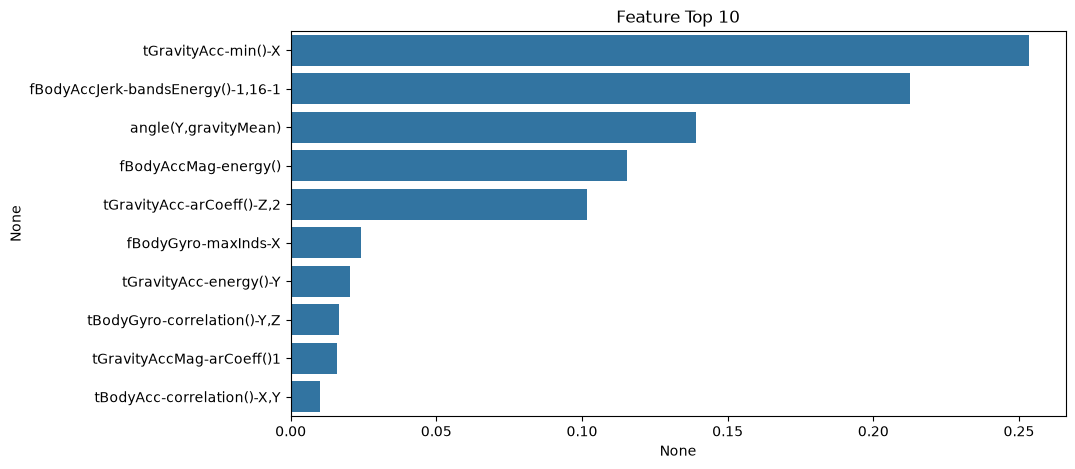

In [17]:
feature_top10 = feature_importance_values_s.sort_values(ascending = False)[:10] # 중요한 피처 상위 10개

plt.figure(figsize=(10, 5))
plt.title('Feature Top 10')
sns.barplot(x = feature_top10, y = feature_top10.index)
plt.show()

In [18]:
import os
# 설치 경로(C:/Program Files/Graphviz/bin)를 PATH에 추가(설치 시 했지만, 안전한 동작을 위해
os.environ["PATH"] += os.pathsep + 'C:/Program Files/Graphviz/bin'

In [19]:
# 실행 파일 호출을 위한 래퍼 모듈
!pip install graphviz

In [22]:
import sys
!{sys.executable} -m pip install graphviz

  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [20]:
from sklearn.tree import export_graphviz

export_graphviz(best_dt_HAR, out_file = "tree.dot", class_names = label_name, feature_names = feature_name, impurity = True, filled = True) # out_file로 지정된 tree.dot 파일 생성(메타 파일)

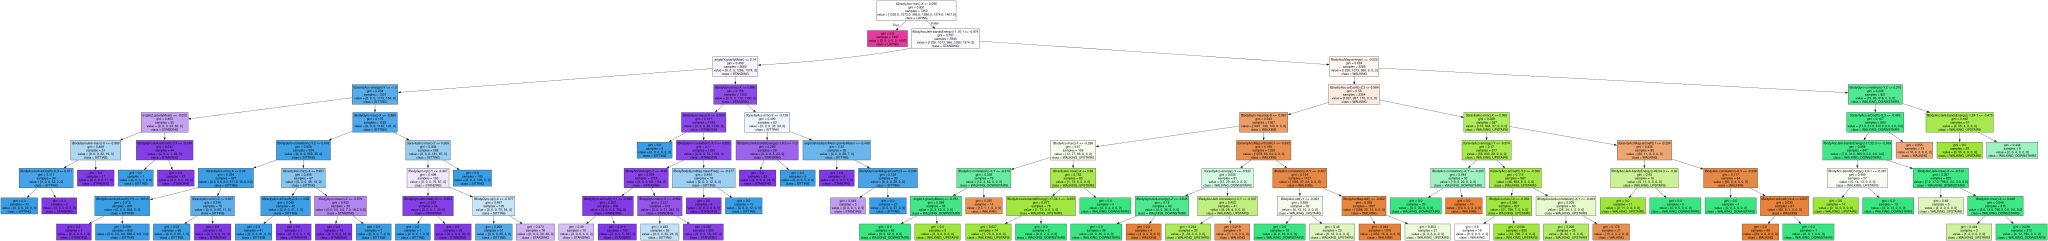

In [23]:
import graphviz

with open('tree.dot') as f: # 생성한 tree.dot 파일을 읽음.
    dot_graph = f.read()

graphviz.Source(dot_graph) # graphviz로 시각화

In [25]:
graphviz.Source(dot_graph).render(filename='tree', format='png') # png로 저장

'tree.png'